In [2]:
!pip install --quiet datasets
%pip install torchvision

import matplotlib.pyplot as plt
from torchvision import transforms

from datasets import load_dataset
from pathlib import Path
import datasets

files = sorted(Path("D:/Dataset").rglob("*.parquet"))

print ("Найдено файлов ", len(files))
ds_stream = load_dataset(
    "parquet",
    data_files={"train": [str(f) for f in files]}
    )
ds_stream["train"] = ds_stream["train"].cast_column(
    "image", datasets.Image(decode=False)
)
    




[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


c:\Users\Max\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Найдено файлов  64


In [3]:
FILTER_WORDS = [
    "nsfw", "naked", "lewd", "undressed", "lingerie",
    "underwear", "panties", "cleavage", "suggestive",
    "bound", "fetish", "chest", "sensual", "exposed"
]

stats = {"filtered_count": 0}

def safe_samples_filter(example):
    caption = example['text'].lower()
    if not any([word in caption for word in FILTER_WORDS]) == False:
        stats['filtered_count'] += 1
        # plt.imshow(example['image'])
        # plt.show()
        return False
    return True

index = 0


In [6]:
import numpy as np
import re
from collections import Counter
from PIL import Image
from io import BytesIO

filtered_dataset = ds_stream["train"].filter(safe_samples_filter)

pixel_hist = np.zeros(256,dtype=np.int64)
word_counts = Counter()

processed = 0
valid_images = 0
image_errors = 0
first_example = None

for example in filtered_dataset:
  if first_example is None:
    first_example = example

  text = str(example["text"].lower())
  words = re.findall(r"[a-z]+", text)
  word_counts.update(words)

  try:
    gray = Image.open(BytesIO(example["image"]["bytes"])).convert("L")
    pixel_hist += np.asarray(gray.histogram(), dtype=np.int64)
    valid_images +=1
  except (OSError, ValueError, TypeError, AttributeError):
    image_errors +=1

  processed +=1
  if processed == 1 or processed%10000==0:
    print("Обработано: ", processed)
print ("Всего подходящих: ", processed)
print("Отфильтровано: ", stats["filtered_count"])
print ("Ошибок изображений: ", image_errors)


Обработано:  1
Обработано:  10000
Обработано:  20000
Обработано:  30000
Обработано:  40000
Обработано:  50000
Обработано:  60000
Обработано:  70000
Обработано:  80000
Обработано:  90000
Обработано:  100000
Обработано:  110000
Обработано:  120000
Обработано:  130000
Обработано:  140000
Обработано:  150000
Обработано:  160000
Обработано:  170000
Обработано:  180000
Обработано:  190000
Обработано:  200000
Обработано:  210000
Обработано:  220000
Обработано:  230000
Обработано:  240000
Обработано:  250000
Обработано:  260000
Обработано:  270000
Обработано:  280000
Обработано:  290000
Обработано:  300000
Обработано:  310000
Всего подходящих:  319033
Отфильтровано:  0
Ошибок изображений:  0


In [7]:
fr = filtered_dataset[0]["text"]
min_words = len(fr.split())
max_words = len(fr.split())

for words in filtered_dataset:
    words = words["text"].split()
    count = len(words)
    min_words = min(min_words, count)
    max_words = max(max_words, count)

print("Минимум слов в запросе:", min_words)
print("Максимум слов в запросе:", max_words)


Минимум слов в запросе: 5
Максимум слов в запросе: 126


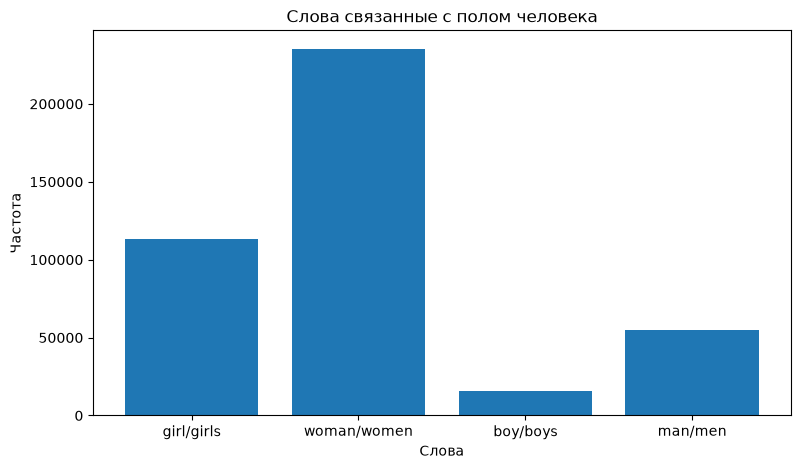

{'girl/girls': 113413, 'woman/women': 235306, 'boy/boys': 15405, 'man/men': 54590}


In [19]:
gender_words ={
    "girl/girls": word_counts["girl"]+word_counts["girls"],
    "woman/women":word_counts["woman"]+word_counts["women"],
    "boy/boys": word_counts["boy"]+word_counts["boys"],
    "man/men": word_counts["man"] + word_counts["men"]
}
plt.figure(figsize=(9,5))

plt.bar(
    gender_words.keys(),
    gender_words.values()
)
plt.title("Слова связанные с полом человека")
plt.xlabel("Слова")
plt.ylabel("Частота")
plt.show()
print(gender_words)
